In [3]:
import os
import struct
import time
import numpy as np
import matplotlib.pyplot as plt


def load_images(filename):
    with open(filename, 'rb') as f:
        magic, num, rows, cols = struct.unpack(">IIII", f.read(16))
        images = np.frombuffer(f.read(), dtype=np.uint8)
        return images.reshape(num, rows * cols)


def load_labels(filename):
    with open(filename, 'rb') as f:
        magic, num = struct.unpack(">II", f.read(8))
        labels = np.frombuffer(f.read(), dtype=np.uint8)
        return labels


try:
    X_train = load_images("train-images.idx3-ubyte")
    y_train = load_labels("train-labels.idx1-ubyte")
    X_test = load_images("t10k-images.idx3-ubyte")
    y_test = load_labels("t10k-labels.idx1-ubyte")
except FileNotFoundError as e:
    print(f"FileNotFoundError: {e}")
    exit()


X_train = X_train / 255.
X_test = X_test / 255.

print(f"TRAIN: {X_train.shape}, {y_train.shape}")
print(f"TEST: {X_test.shape}, {y_test.shape}")

TRAIN: (60000, 784), (60000,)
TEST: (10000, 784), (10000,)


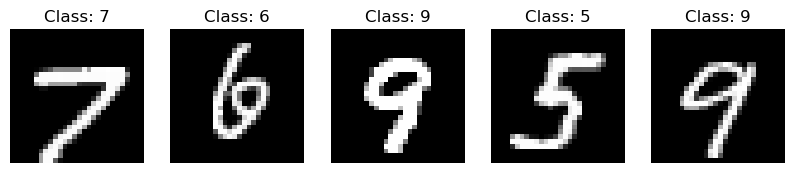

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(10, 3))
for i, ax in enumerate(axes):
    idx = np.random.randint(0, len(X_train))
    ax.imshow(X_train[idx].reshape(28, 28), cmap='gray')
    ax.set_title(f"Class: {y_train[idx]}")
    ax.axis('off')
plt.show()

In [5]:
class TwoLayerNet:
    def __init__(self, input_dim=784, hidden_dim=300, output_dim=10):
        self.w1 = np.random.randn(input_dim, hidden_dim) * np.sqrt(2./input_dim)
        self.b1 = np.zeros((1, hidden_dim))
        self.w2 = np.random.randn(hidden_dim, output_dim) * np.sqrt(2./hidden_dim)
        self.b2 = np.zeros((1, output_dim))

    def relu(self, Z):
        return np.maximum(0, Z)

    def relu_der(self, Z):
        return (Z > 0).astype(float)

    def softmax(self, Z):
        exp_Z = np.exp(Z - np.max(Z, axis=1, keepdims=True))
        return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

    def forward(self, X):
        self.Z1 = np.dot(X, self.w1) + self.b1
        self.A1 = self.relu(self.Z1)
        self.Z2 = np.dot(self.A1, self.w2) + self.b2
        self.A2 = self.softmax(self.Z2)
        return self.A2

    def backward(self, X, y, A2):
        m = y.shape[0]
        Y = np.zeros_like(A2)
        Y[np.arange(m), y] = 1

        dZ2 = (A2 - Y) / m
        dw2 = np.dot(self.A1.T, dZ2)
        db2 = np.sum(dZ2, axis=0, keepdims=True)

        dA1 = np.dot(dZ2, self.w2.T)
        dZ1 = dA1 * self.relu_der(self.Z1)
        dw1 = np.dot(X.T, dZ1)
        db1 = np.sum(dZ1, axis=0, keepdims=True)

        return dw1, db1, dw2, db2

    def upd_params(self, dw1, db1, dw2, db2, lr):
        self.w1 -= lr * dw1
        self.b1 -= lr * db1
        self.w2 -= lr * dw2
        self.b2 -= lr * db2

    def eval(self, X, y):
        preds = self.forward(X)
        predictions = np.argmax(preds, axis=1)
        return np.mean(predictions == y)

In [6]:
BATCH_SIZE = 64
LEARNING_RATE = 0.1
HIDDEN_NEURONS = 300
EPOCHS = 20

model = TwoLayerNet(input_dim=784, hidden_dim=HIDDEN_NEURONS, output_dim=10)
num_samples = X_train.shape[0]

for epoch in range(EPOCHS):
    start_time = time.time()

    permutation = np.random.permutation(num_samples)
    X_train_shuffle = X_train[permutation]
    y_train_shuffle = y_train[permutation]

    for i in range(0, num_samples, BATCH_SIZE):
        X_batch = X_train_shuffle[i:i+BATCH_SIZE]
        y_batch = y_train_shuffle[i:i+BATCH_SIZE]

        outputs = model.forward(X_batch)
        dw1, db1, dw2, db2 = model.backward(X_batch, y_batch, outputs)
        model.upd_params(dw1, db1, dw2, db2, LEARNING_RATE)

    epoch_time = time.time() - start_time
    train_acc = model.eval(X_train, y_train)
    print(f"EPOCH {epoch+1:02d}/{EPOCHS} | TRAIN ACCURACY: {train_acc*100:.2f}% | EPOCH TIME: {epoch_time:.2f} sec")

test_acc = model.eval(X_test, y_test)
print("\n" + "="*50)
print(f"TOTAL ACCURACY ON TEST: {test_acc*100:.2f}%")
print("="*50)

EPOCH 01/20 | TRAIN ACCURACY: 93.77% | EPOCH TIME: 4.55 sec
EPOCH 02/20 | TRAIN ACCURACY: 95.74% | EPOCH TIME: 5.97 sec
EPOCH 03/20 | TRAIN ACCURACY: 96.82% | EPOCH TIME: 1.95 sec
EPOCH 04/20 | TRAIN ACCURACY: 97.38% | EPOCH TIME: 1.76 sec
EPOCH 05/20 | TRAIN ACCURACY: 97.84% | EPOCH TIME: 1.69 sec
EPOCH 06/20 | TRAIN ACCURACY: 98.11% | EPOCH TIME: 1.68 sec
EPOCH 07/20 | TRAIN ACCURACY: 98.31% | EPOCH TIME: 1.61 sec
EPOCH 08/20 | TRAIN ACCURACY: 98.70% | EPOCH TIME: 1.57 sec
EPOCH 09/20 | TRAIN ACCURACY: 98.79% | EPOCH TIME: 1.59 sec
EPOCH 10/20 | TRAIN ACCURACY: 99.00% | EPOCH TIME: 1.72 sec
EPOCH 11/20 | TRAIN ACCURACY: 99.05% | EPOCH TIME: 1.53 sec
EPOCH 12/20 | TRAIN ACCURACY: 99.15% | EPOCH TIME: 1.56 sec
EPOCH 13/20 | TRAIN ACCURACY: 99.38% | EPOCH TIME: 1.54 sec
EPOCH 14/20 | TRAIN ACCURACY: 99.39% | EPOCH TIME: 1.56 sec
EPOCH 15/20 | TRAIN ACCURACY: 99.50% | EPOCH TIME: 1.57 sec
EPOCH 16/20 | TRAIN ACCURACY: 99.45% | EPOCH TIME: 1.56 sec
EPOCH 17/20 | TRAIN ACCURACY: 99.53% | E